<a href="https://colab.research.google.com/github/khillon-makwana/SemProject_MLEngine/blob/main/LogisticRegression_Base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PathFinder: AI Career Path Recommendation**


**Group Members:**
- 191608 - Nehemiah Joel Wanjala
- 193428 - Suraj Kumar Menariya
- 183870 - Khillon Jayesh Makwana


**Dataset used:** Stack Overflow Developer Survey (2025)

**Connecting Google Drive**

In [2]:
# Connecting Google Drive so we can load the dataset
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Q1: ML Approach and Algorithms

- Problem type: Supervised learning, multi-class classification. It is done in two steps. First the model picks one of 5 career areas, then a smaller model ranks the careers inside that area
- Inputs: skills the person uses (languages, databases, platforms, frameworks, dev tools), skills they want to work with, operating system, AI tools and other tools they use, years of coding, work experience and education
- Output: a percentage for each career area and for each career inside it. The app also shows a fit label (Strong fit, Good fit or Possible fit), a description of the career and the skills to learn next
- Base model: Logistic Regression with class weights
- Compared models: Naive Bayes, KNN, Decision Tree, Random Forest, Neural Network, HistGradientBoosting, LightGBM and a combined model (Logistic Regression + HistGradientBoosting + LightGBM)
- Metrics: Macro F1 (main score), Accuracy, Top-2 accuracy

# Q2: Data Cleaning and EDA

## Data Exploration Stage

**Loading the Dataset**

Here the Stack Overflow Developer Survey dataset is loaded. It has 49,123 people and 170 columns. Each row is one developer, their job role and the skills they use. Their job role is what is to be predicted. The app will ask the user about their skills, the skills they want to learn, their experience and their education.

In [3]:
import pandas as pd

# Loading the survey data and checking its size
df = pd.read_csv("/content/drive/MyDrive/survey_results_public.csv", low_memory=False)
print(df.shape)
df.head()

(49123, 170)


,ResponseId,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,...,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,"Caring for dependents (children, elderly, etc.)",8.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,Vertex AI,NaN,NaN,NaN,ChatGPT,NaN,When I don’t trust AI’s answers,"Troubleshooting, profiling, debugging",61256.0,10.0
1,2,I am a developer by profession,25-34 years old,"Associate degree (A.A., A.S., etc.)",Employed,NaN,2.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I want to...,All skills. AI is a flop.,104413.0,9.0
2,3,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Independent contractor, freelancer, or self-em...",None of the above,10.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code;GitHub Copilot;Google Gemini,NaN,When I don’t trust AI’s answers;When I want to...,"Understand how things actually work, problem s...",53061.0,8.0
3,4,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,None of the above,4.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code,NaN,When I don’t trust AI’s answers;When I want to...,NaN,36197.0,6.0
4,5,I am a developer by profession,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...","Caring for dependents (children, elderly, etc.)",21.0,"No, I am not new to coding and did not learn n...",NaN,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers,"critical thinking, the skill to define the tas...",60000.0,7.0


**Exploring the Job Roles**

5,487 people did not give a job role. There are 32 different roles. Some of these roles in the dataset are not careers a student can train for. For example "Student", "Retired", "Senior executive". These need to be removed.

In [4]:
# Counting missing job roles and seeing how many people are in each role
print("Missing job roles:", df["DevType"].isna().sum())
print("Number of job roles:", df["DevType"].nunique())
df["DevType"].value_counts()

Missing job roles: 5487
Number of job roles: 32


,count
DevType,
"Developer, full-stack",12339
"Developer, back-end",6446
Student,3003
"Architect, software or solutions",2680
"Developer, front-end",1972
"Developer, desktop or enterprise applications",1918
Other (please specify):,1823
"Developer, mobile",1389
"Developer, embedded applications or devices",1273


**Checking for Missing Values**

Out of all the columns, we focused on the 19 columns that match what the app can ask a student. These are the skills a person uses, the skills they want to work with, their operating system, the AI and other tools they use, and their experience and education.

The skill columns have a lot of missing values. A blank value under a skill column means that the person did not tick anything in that section, it is not that the data was lost. The "want to work with" and AI questions have the most blanks (up to 72.4%) because many people skipped them. Experience and education columns are missing as well but not as much

In [5]:
# Skill questions: what the person uses and what they want to work with
used_columns = ["LanguageHaveWorkedWith", "DatabaseHaveWorkedWith", "PlatformHaveWorkedWith",
                "WebframeHaveWorkedWith", "DevEnvsHaveWorkedWith"]
wanted_columns = ["LanguageWantToWorkWith", "DatabaseWantToWorkWith", "PlatformWantToWorkWith",
                  "WebframeWantToWorkWith", "DevEnvsWantToWorkWith"]

# Other questions a student can also answer
other_columns = ["OpSysPersonal use", "SOTagsHaveWorkedWith", "SOTagsWantToWorkWith",
                 "AIModelsHaveWorkedWith", "OfficeStackAsyncHaveWorkedWith"]

# The columns that match what the app can ask a student
columns = (["DevType"] + used_columns + wanted_columns + other_columns
           + ["YearsCode", "WorkExp", "EdLevel"])
missing = df[columns].isna().mean() * 100
print(missing.round(1).sort_values(ascending=False))

SOTagsWantToWorkWith              72.4
AIModelsHaveWorkedWith            66.9
WebframeWantToWorkWith            64.1
SOTagsHaveWorkedWith              63.5
PlatformWantToWorkWith            60.5
DatabaseWantToWorkWith            59.9
DevEnvsWantToWorkWith             58.1
WebframeHaveWorkedWith            53.2
PlatformHaveWorkedWith            50.7
DatabaseHaveWorkedWith            48.0
DevEnvsHaveWorkedWith             47.1
LanguageWantToWorkWith            44.9
OfficeStackAsyncHaveWorkedWith    39.3
OpSysPersonal use                 36.1
LanguageHaveWorkedWith            35.6
WorkExp                           12.8
YearsCode                         12.5
DevType                           11.2
EdLevel                            2.1
dtype: float64


## Data Cleaning Stage

**Removing unnecessary columns and keeping only the ones needed**

We kept only 19 of the 170 columns. Columns like salary, country and company size are dropped because a student using the app may not have that information so the model should not depend on it

In [6]:
# Keeping only the columns we need
data = df[columns].copy()
print(data.shape)

(49123, 19)


**Removing rows that have no job role**

A row without a job role has no answer to learn from so we remove it. We go from 49,123 to 43,636 rows

In [7]:
# Removing people who did not give a job role
data = data.dropna(subset=["DevType"])
print(data.shape)

(43636, 19)


**Removing rows that have no programming language**

Programming languages tell us the most about what career someone is in. If a person didn't list any languages then there isn't much for the model to learn from. Because of that, we removed them. We go from 43,636 to 31,643 rows

In [8]:
# Removing people who did not list any programming language
data = data.dropna(subset=["LanguageHaveWorkedWith"])
print(data.shape)

(31643, 19)


**Removing the roles that are not careers**

We removed students, retired people, people who chose "Other" and management or business roles like executives, founders, managers, financial analysts and UX designers. People get these jobs because of their experience or business skills and not their technical skills so the model cannot predict them from what a student knows. This took us from 31,643 to 26,071 rows

In [9]:
# Roles that are not technical careers a student can train for
remove_roles = ["Student", "Retired", "Other (please specify):",
                "Senior executive (C-suite, VP, etc.)", "Founder, technology or otherwise",
                "Engineering manager", "Project manager", "Product manager",
                "Financial analyst or engineer", "UX, Research Ops or UI design professional"]
data = data[~data["DevType"].isin(remove_roles)]
print(data.shape)

(26071, 19)


**Grouping similar roles into careers**

Some roles are very similar and use the same skills. For example, "Data scientist", "AI/ML engineer" and "Applied scientist" all work with data and machine learning, and they use tools like Python, Jupyter and SQL. Since our model only looks at skills, it cannot tell these people apart, so we joined them into one career.

Other roles had very few people. The model needs a lot of examples to learn which skills go with a career. With only a few people, it doesn't learn the role well and rarely predicts it correctly. For example, "System administrator" and "Cloud infrastructure engineer" were small groups that do similar work to "DevOps engineer", so we put all three into one career called DevOps/Cloud Engineer.

After joining similar roles together, we had 15 careers

In [10]:
# Matching each survey role to one of our 15 careers
# Similar roles are given the same career name
career_names = {
    "Developer, full-stack": "Full-stack Developer",
    "Developer, back-end": "Back-end Developer",
    "Developer, front-end": "Front-end Developer",
    "Developer, mobile": "Mobile Developer",
    "Developer, desktop or enterprise applications": "Desktop/Enterprise Developer",
    "Developer, embedded applications or devices": "Embedded Systems Developer",
    "Developer, game or graphics": "Game/Graphics Developer",
    "Developer, QA or test": "QA/Test Engineer",
    "DevOps engineer or professional": "DevOps/Cloud Engineer",
    "Cloud infrastructure engineer": "DevOps/Cloud Engineer",
    "System administrator": "DevOps/Cloud Engineer",
    "Data scientist": "Data Scientist / AI-ML Engineer",
    "AI/ML engineer": "Data Scientist / AI-ML Engineer",
    "Applied scientist": "Data Scientist / AI-ML Engineer",
    "Developer, AI apps or physical AI": "Data Scientist / AI-ML Engineer",
    "Data engineer": "Data Engineer/Analyst",
    "Data or business analyst": "Data Engineer/Analyst",
    "Database administrator or engineer": "Data Engineer/Analyst",
    "Cybersecurity or InfoSec professional": "Cybersecurity Specialist",
    "Support engineer or analyst": "IT Support Engineer",
    "Architect, software or solutions": "Software Architect",
    "Academic researcher": "Academic Researcher",
}

# Creating the new Career column and removing the original role column
data["Career"] = data["DevType"].map(career_names)
data = data.drop(columns="DevType")
data["Career"].value_counts()

,count
Career,
Full-stack Developer,9105
Back-end Developer,4688
Software Architect,2018
Desktop/Enterprise Developer,1488
DevOps/Cloud Engineer,1453
Front-end Developer,1401
Data Scientist / AI-ML Engineer,1249
Embedded Systems Developer,967
Mobile Developer,929


**Grouping careers into career areas**

Even after grouping roles into 15 careers, many careers still share most of their skills. For example, Full-stack, Front-end and Back-end developers all use JavaScript, HTML/CSS and SQL. Our first model often mixed these careers up and its Macro F1 was only 34.8%.

So we grouped the careers into 5 career areas. Careers in the same area use similar skills, while the areas themselves are quite different from each other. The app first finds the student's area and then ranks the careers inside it (step 2 below).

We also removed QA/Test. It had only 249 people and its skills look like everyone else's, so the model almost never predicted it correctly. This left us with 25,822 rows

In [11]:
# Putting careers that share the same skills into one career area
career_areas = {
    "Full-stack Developer": "Web Development",
    "Front-end Developer": "Web Development",
    "Back-end Developer": "Web Development",
    "Software Architect": "Web Development",
    "Data Scientist / AI-ML Engineer": "Data & AI",
    "Data Engineer/Analyst": "Data & AI",
    "Academic Researcher": "Data & AI",
    "DevOps/Cloud Engineer": "Cloud & Infrastructure",
    "Cybersecurity Specialist": "Cloud & Infrastructure",
    "IT Support Engineer": "Cloud & Infrastructure",
    "Mobile Developer": "Mobile Development",
    "Embedded Systems Developer": "Systems, Embedded & Games",
    "Desktop/Enterprise Developer": "Systems, Embedded & Games",
    "Game/Graphics Developer": "Systems, Embedded & Games",
}

# Removing QA/Test, which the model could not learn
data = data[data["Career"] != "QA/Test Engineer"]
data["Area"] = data["Career"].map(career_areas)
print(data.shape)
data["Area"].value_counts()

(25822, 20)


,count
Area,
Web Development,17212
Data & AI,2994
"Systems, Embedded & Games",2784
Cloud & Infrastructure,1903
Mobile Development,929


**Cleaning years of coding and work experience fields**

Where years of coding or work experience were missing, we filled them in with the median (the middle value) which is 15 years of coding and 11 years of work. We used the median instead of the average because a few people with a lot of experience would pull the average up. Some people also entered 100 years, which is not realistic, so we set the highest allowed value to 50.

In [12]:
# Summary before cleaning
print(data[["YearsCode", "WorkExp"]].describe())

# Filling missing values with the median
data["YearsCode"] = data["YearsCode"].fillna(data["YearsCode"].median())
data["WorkExp"] = data["WorkExp"].fillna(data["WorkExp"].median())

# Capping unrealistic values at 50 years
data["YearsCode"] = data["YearsCode"].clip(upper=50)
data["WorkExp"] = data["WorkExp"].clip(upper=50)

# Summary after cleaning
print(data[["YearsCode", "WorkExp"]].describe())

          YearsCode       WorkExp
count  25592.000000  25074.000000
mean      17.667201     13.608878
std       11.256833     10.350364
min        1.000000      1.000000
25%        9.000000      5.000000
50%       15.000000     11.000000
75%       25.000000     20.000000
max      100.000000    100.000000
          YearsCode       WorkExp
count  25822.000000  25822.000000
mean      17.602200     13.507629
std       11.032204     10.073280
min        1.000000      1.000000
25%        9.000000      5.000000
50%       15.000000     11.000000
75%       25.000000     20.000000
max       50.000000     50.000000


**Turning education into numbers**

Education levels go from low to high, so we gave each one a number from 0 (primary school) to 5 (PhD or professional degree). Only a few people did not give their education so we filled those in with the median, which was 3 (a Bachelor's degree).

In [13]:
# Giving each education level a number from lowest to highest
education_levels = {
    "Primary/elementary school": 0,
    "Secondary school": 1,
    "Some college/university study without earning a degree": 2,
    "Associate degree (A.A., A.S., etc.)": 2,
    "Bachelor’s degree (B.A., B.S., B.Eng., etc.)": 3,
    "Master’s degree (M.A., M.S., M.Eng., MBA, etc.)": 4,
    "Professional degree (JD, MD, Ph.D, Ed.D, etc.)": 5,
}
data["EdLevel"] = data["EdLevel"].map(education_levels)

# Filling missing education with the median
data["EdLevel"] = data["EdLevel"].fillna(data["EdLevel"].median())
data["EdLevel"].value_counts().sort_index()

,count
EdLevel,
0.0,148
2.0,3900
3.0,12919
4.0,7384
5.0,1471


**Removing duplicate rows**

No duplicate rows were found this time. Now that each person has many more columns, no two people gave exactly the same answers

In [14]:
print("Before:", len(data))
data = data.drop_duplicates()
print("After:", len(data))

Before: 25822
After: 25822


**Turning skills into 0 or 1 columns**

Each skill column had a list of skills in one cell, like "Python;SQL;Java". We split them so that every skill has its own column. If a person uses that skill they get a 1 and if they do not then they get a 0. If someone left a skill question blank, they get a 0 for every skill in that group.

We did the same for the skills people want to work with and for the other questions. Each column has a prefix to show which question it came from, for example "Language_Python" means the person uses Python and "WantLanguage_Python" means they want to work with it. This gave us 435 columns

In [15]:
# Splitting each list of skills the person uses into separate 0/1 columns
languages = data["LanguageHaveWorkedWith"].str.get_dummies(sep=";")
databases = data["DatabaseHaveWorkedWith"].str.get_dummies(sep=";")
platforms = data["PlatformHaveWorkedWith"].str.get_dummies(sep=";")
webframes = data["WebframeHaveWorkedWith"].str.get_dummies(sep=";")
devtools = data["DevEnvsHaveWorkedWith"].str.get_dummies(sep=";")

# Doing the same for the skills the person wants to work with
want_languages = data["LanguageWantToWorkWith"].str.get_dummies(sep=";")
want_databases = data["DatabaseWantToWorkWith"].str.get_dummies(sep=";")
want_platforms = data["PlatformWantToWorkWith"].str.get_dummies(sep=";")
want_webframes = data["WebframeWantToWorkWith"].str.get_dummies(sep=";")
want_devtools = data["DevEnvsWantToWorkWith"].str.get_dummies(sep=";")

# And for the other questions
systems = data["OpSysPersonal use"].str.get_dummies(sep=";")
topics = data["SOTagsHaveWorkedWith"].str.get_dummies(sep=";")
want_topics = data["SOTagsWantToWorkWith"].str.get_dummies(sep=";")
ai_models = data["AIModelsHaveWorkedWith"].str.get_dummies(sep=";")
office_tools = data["OfficeStackAsyncHaveWorkedWith"].str.get_dummies(sep=";")

# Joining all skill columns, adding a prefix to show which question each one is from
skills = pd.concat([languages.add_prefix("Language_"),
                    databases.add_prefix("Database_"),
                    platforms.add_prefix("Platform_"),
                    webframes.add_prefix("Webframe_"),
                    devtools.add_prefix("DevEnvs_"),
                    want_languages.add_prefix("WantLanguage_"),
                    want_databases.add_prefix("WantDatabase_"),
                    want_platforms.add_prefix("WantPlatform_"),
                    want_webframes.add_prefix("WantWebframe_"),
                    want_devtools.add_prefix("WantDevEnvs_"),
                    systems.add_prefix("OS_"),
                    topics.add_prefix("Topic_"),
                    want_topics.add_prefix("WantTopic_"),
                    ai_models.add_prefix("AIModel_"),
                    office_tools.add_prefix("OfficeTool_")], axis=1)
print("Skill columns:", skills.shape[1])

Skill columns: 435


**Removing very rare skills**

We removed skills that less than 0.5% of people use. 5 columns were removed. Very few people use them and the model can't learn anything useful from them. They would confuse the model. 430 skill columns were left

In [16]:
# Finding and removing skills used by fewer than 0.5% of people
usage = skills.mean()
rare_skills = usage[usage < 0.005].index
skills = skills.drop(columns=rare_skills)
print("Removed:", len(rare_skills), "columns")
print("Skill columns left:", skills.shape[1])

Removed: 5 columns
Skill columns left: 430


**Final dataset after cleaning**

We added one more column called SkillCount which is the number of skills each person uses. Our final dataset after cleaning contained 25,822 people, 434 columns (430 skill columns and 4 number columns), 5 career areas and no missing values

In [17]:
# Counting how many skills each person uses (only the skills they have, not the ones they want)
used_prefixes = ("Language_", "Database_", "Platform_", "Webframe_", "DevEnvs_")
used_skill_columns = [c for c in skills.columns if c.startswith(used_prefixes)]
data["SkillCount"] = skills[used_skill_columns].sum(axis=1)

# X holds the inputs for the model, y holds the career area to predict
X = pd.concat([skills, data[["YearsCode", "WorkExp", "EdLevel", "SkillCount"]]], axis=1)
y = data["Area"]

# The specific career is kept for step 2 and for the EDA
careers = data["Career"]

print("X:", X.shape)
print("y:", y.shape)
print("Missing values:", X.isna().sum().sum())

X: (25822, 434)
y: (25822,)
Missing values: 0


## EDA Observations

**Observation 1: Number of people in each career area**

The career areas are not balanced. Web Development makes up 66.7% of the data while Mobile Development is only 3.6%. This means a model that just guessed "Web Development" every time would already be right 66.7% of the time without learning anything. This is why we use Macro F1 as our main score and give smaller areas more weight when training

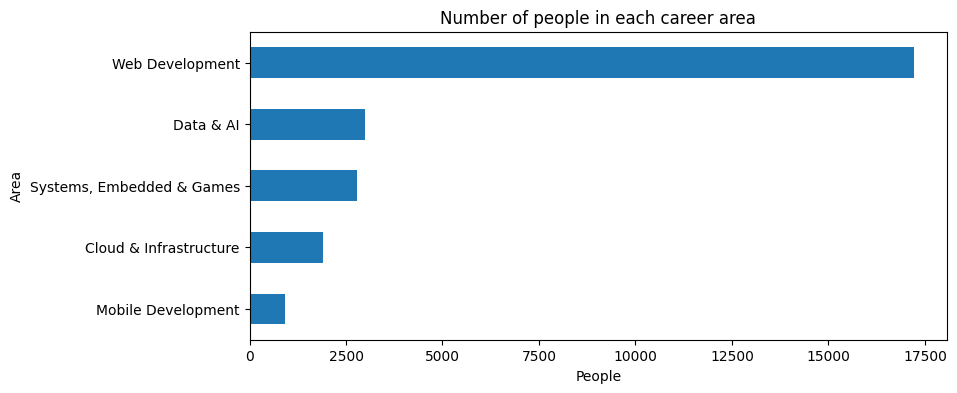

Area
Web Development              66.7
Data & AI                    11.6
Systems, Embedded & Games    10.8
Cloud & Infrastructure        7.4
Mobile Development            3.6
Name: count, dtype: float64


In [18]:
import matplotlib.pyplot as plt

# Plotting the number of people in each career area
counts = y.value_counts()
counts.plot(kind="barh", figsize=(9, 4))
plt.gca().invert_yaxis()
plt.title("Number of people in each career area")
plt.xlabel("People")
plt.show()

# Showing each area as a percentage of the data
print((counts / len(y) * 100).round(1))

**Observation 2: Languages used in each career**

Languages point to certain careers. Swift, Kotlin and Dart are mostly used by Mobile Developers. C is used a lot by Embedded Systems Developers, and Python is used a lot by Data Scientists. JavaScript and TypeScript are used in many different careers so on their own they don't tell us much about which career someone is in. This shows that the skills a person has are the most useful thing for predicting their career

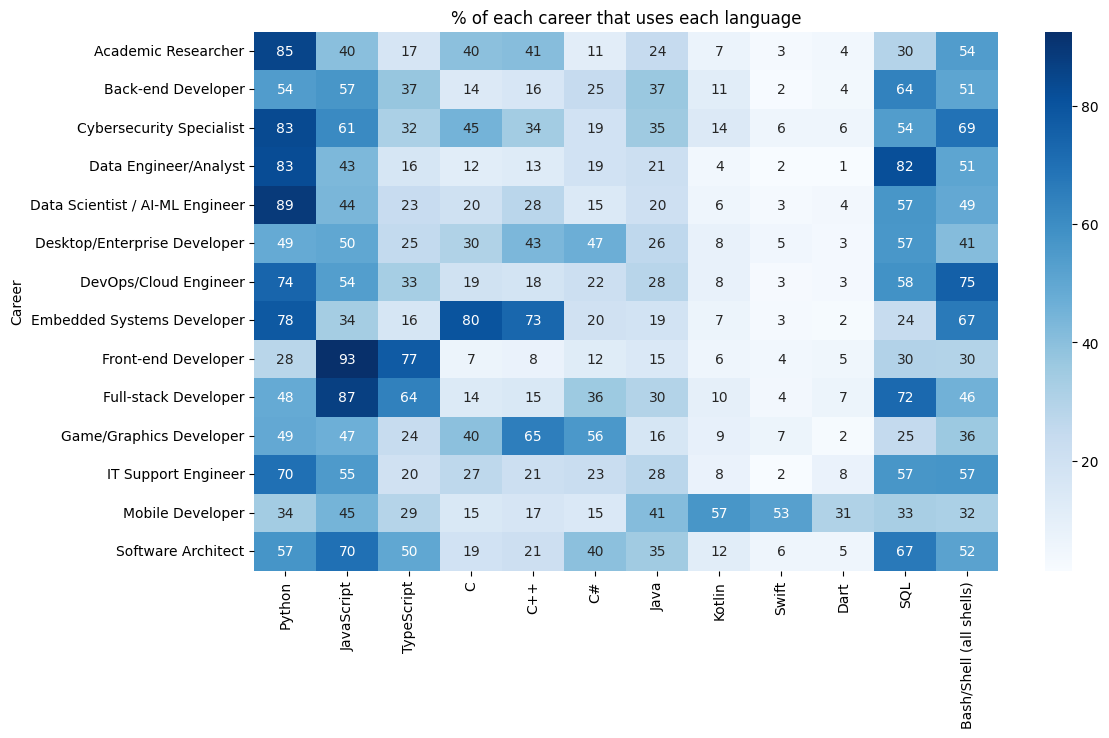

In [19]:
import seaborn as sns

# Percentage of people in each career who use each language
language_use = languages.groupby(careers).mean() * 100
main_languages = ["Python", "JavaScript", "TypeScript", "C", "C++", "C#", "Java",
                  "Kotlin", "Swift", "Dart", "SQL", "Bash/Shell (all shells)"]

plt.figure(figsize=(12, 7))
sns.heatmap(language_use[main_languages], annot=True, fmt=".0f", cmap="Blues")
plt.title("% of each career that uses each language")
plt.show()

**Observation 3: Work experience in each career**

Work experience does not tell the careers apart very well. In most careers, the middle value is between 9 and 12 years. The ones that stand out are Desktop/Enterprise Developer at 14.5 years and Software Architect at 20 years, because these are roles people usually move into after many years of work. So experience helps the model spot careers like architects but it does not help much with the other careers

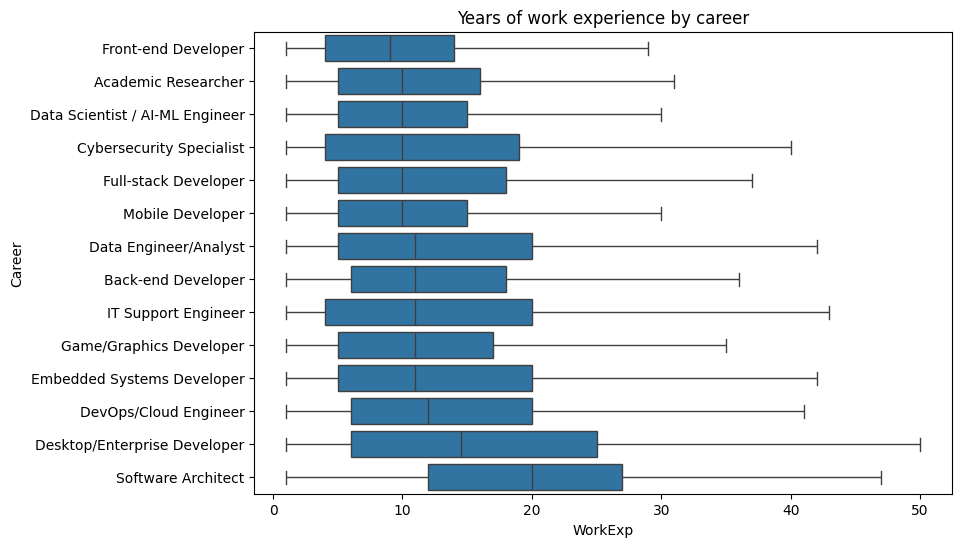

Career
Front-end Developer                 9.0
Academic Researcher                10.0
Data Scientist / AI-ML Engineer    10.0
Cybersecurity Specialist           10.0
Full-stack Developer               10.0
Mobile Developer                   10.0
Data Engineer/Analyst              11.0
Back-end Developer                 11.0
IT Support Engineer                11.0
Game/Graphics Developer            11.0
Embedded Systems Developer         11.0
DevOps/Cloud Engineer              12.0
Desktop/Enterprise Developer       14.5
Software Architect                 20.0
Name: WorkExp, dtype: float64


In [20]:
# Ordering careers by median work experience
order = data.groupby("Career")["WorkExp"].median().sort_values().index

plt.figure(figsize=(9, 6))
sns.boxplot(data=data, x="WorkExp", y="Career", order=order, showfliers=False)
plt.title("Years of work experience by career")
plt.show()

print(data.groupby("Career")["WorkExp"].median().sort_values())

**Observation 4: Education in each career**

Education is helpful in research careers. 78.5% of Academic Researchers and 64.9% of Data Scientists have a Master's or PhD. For Front-end and Full-stack developers it is only about 25%. This helps the model tell apart the research and data careers from developer careers

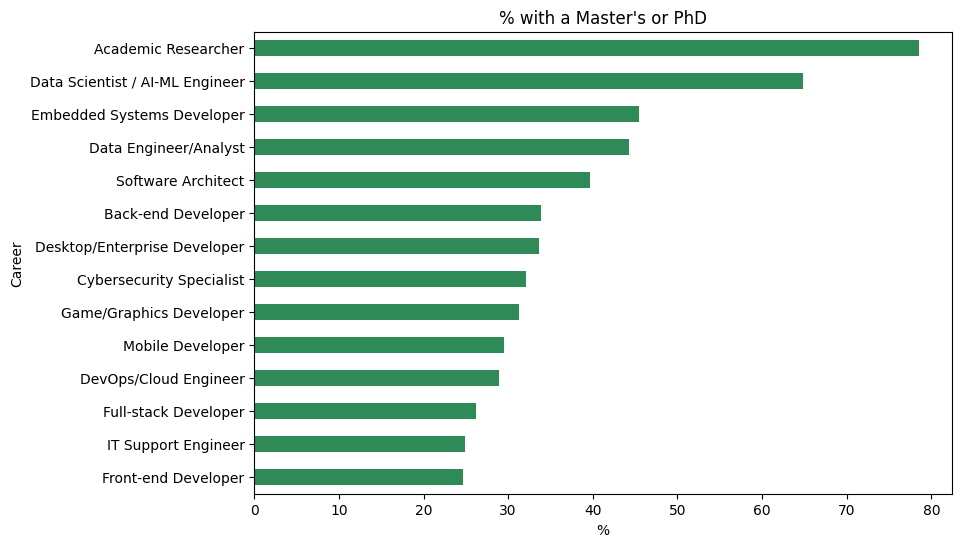

Career
Front-end Developer                24.7
IT Support Engineer                24.9
Full-stack Developer               26.2
DevOps/Cloud Engineer              28.9
Mobile Developer                   29.5
Game/Graphics Developer            31.3
Cybersecurity Specialist           32.1
Desktop/Enterprise Developer       33.7
Back-end Developer                 33.9
Software Architect                 39.7
Data Engineer/Analyst              44.3
Embedded Systems Developer         45.5
Data Scientist / AI-ML Engineer    64.9
Academic Researcher                78.5
Name: Postgraduate, dtype: float64


In [21]:
# Marking people with a Master's or PhD (education level 4 or above)
data["Postgraduate"] = data["EdLevel"] >= 4
postgrad = data.groupby("Career")["Postgraduate"].mean().sort_values() * 100

# Percentage of each career with a Master's or PhD
postgrad.plot(kind="barh", figsize=(9, 6), color="seagreen")
plt.title("% with a Master's or PhD")
plt.xlabel("%")
plt.show()

print(postgrad.round(1))

**Observation 5: Languages people use vs languages they want to learn**

What people want to learn is not the same as what they already use. JavaScript is used by 66.8% of people but only 33.3% want to keep working with it. Rust and Go are the opposite. Only 13.9% use Rust but 28.3% want to work with it, and Go goes from 16.9% to 23.9%. This shows that the "want to work with" questions tell us something new about a person's interests, which is why we added them to the model

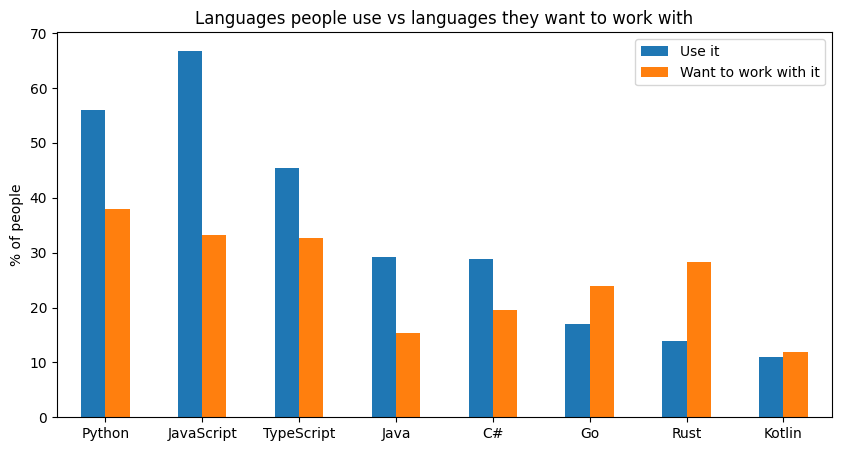

            Use it  Want to work with it
Python        56.0                  37.9
JavaScript    66.8                  33.3
TypeScript    45.5                  32.6
Java          29.2                  15.3
C#            28.8                  19.6
Go            16.9                  23.9
Rust          13.9                  28.3
Kotlin        11.0                  11.9


In [22]:
# Percentage of people who use each language and who want to work with it
compare_languages = ["Python", "JavaScript", "TypeScript", "Java", "C#", "Go", "Rust", "Kotlin"]
use_vs_want = pd.DataFrame({
    "Use it": languages[compare_languages].mean() * 100,
    "Want to work with it": want_languages[compare_languages].mean() * 100,
})

use_vs_want.plot(kind="bar", figsize=(10, 5))
plt.title("Languages people use vs languages they want to work with")
plt.ylabel("% of people")
plt.xticks(rotation=0)
plt.show()

print(use_vs_want.round(1))

# Q3: Our Base Model: Logistic Regression

## Modelling Approach

We chose Logistic Regression as our main model for two reasons:

- It gives a percentage for every career area, so the app can show the student their best areas.
- It is easy to explain. We can see which skills lead someone towards each area.

The model works in two steps. First it picks the career area. Then a smaller Logistic Regression model inside that area ranks the careers in it.

We check how well it does using three scores:

- Macro F1: how well the model does on each of the 5 areas, averaged out. Small areas count just as much as big ones. This is our main score because Web Development is much bigger than the other areas.
- Accuracy: how often the model's first guess is the right area.
- Top-2 accuracy: how often the right area is in the model's top 2. The app shows the 2 best areas.

**Splitting into training and testing data**

We used 80% of the data to train the model and kept the other 20% for testing. We used stratify=y so that each area makes up the same share of both parts. This matters because some areas have far fewer people and without it they could end up with too few people in the test data

In [23]:
from sklearn.model_selection import train_test_split

# 80% for training, 20% for testing, with the same area mix in both
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (20657, 434)
Test: (5165, 434)


**Scaling the number columns**

The skill columns only have 0 or 1 but years of experience can go up to 50. If we left it like this, the model would pay more attention to the bigger numbers. So we scaled the 4 number columns (years coding, work experience, education and skill count) to bring them to a similar range as the skills

In [24]:
from sklearn.preprocessing import StandardScaler

number_columns = ["YearsCode", "WorkExp", "EdLevel", "SkillCount"]
scaler = StandardScaler()

# Scaling the number columns using the training data only
X_train = X_train.copy()
X_test = X_test.copy()
X_train[number_columns] = scaler.fit_transform(X_train[number_columns])
X_test[number_columns] = scaler.transform(X_test[number_columns])

**Baseline**

The baseline always guesses the most common area (Web Development). It gets 66.7% accuracy but only 16.0% Macro F1, because it gets every other area wrong. Our model must beat this to be useful

In [25]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

# A simple model that always guesses the most common area
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)
baseline_accuracy = accuracy_score(y_test, baseline_predictions)
baseline_f1 = f1_score(y_test, baseline_predictions, average="macro")
print("Baseline accuracy:", round(baseline_accuracy, 3))
print("Baseline Macro F1:", round(baseline_f1, 3))

Baseline accuracy: 0.667
Baseline Macro F1: 0.16


**Giving smaller areas more weight**

Web Development has far more people than the other areas, so the model could do well just by leaning towards it. To stop this, we give people from smaller areas more weight when training. Mobile Development gets the most weight (2.36) and Web Development the least (0.55).

We tested full balancing too, but it went too far and made the model guess small areas too often, so we use weights at half the strength

In [26]:
# Smaller areas get a bigger weight, at half the strength of fully balanced weights
area_counts = y_train.value_counts()
area_weights = (len(y_train) / (len(area_counts) * area_counts)) ** 0.5
print(area_weights.round(2))

# One weight for each person in the training data
sample_weights = y_train.map(area_weights).values

Area
Web Development              0.55
Data & AI                    1.31
Systems, Embedded & Games    1.36
Cloud & Infrastructure       1.65
Mobile Development           2.36
Name: count, dtype: float64


**Finding the best regularization value (C)**

Regularisation stops the model from memorising the training data. The C value controls how much of it we use: a small C keeps the model simple, and a big C lets it fit the training data more closely.

We tried 5 values of C using 5-fold cross-validation. This means we split the training data into 5 parts and took turns using each part for testing. The area weights were used every time. C = 0.01 gave the best Macro F1 (0.634)

In [27]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression

# Splitting the training data into 5 parts for cross-validation
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Testing each C value and scoring it using Macro F1
rows = []
for C in [0.001, 0.01, 0.1, 1, 10]:
    cv = cross_validate(LogisticRegression(max_iter=3000, C=C), X_train, y_train, cv=folds,
                        scoring="f1_macro", return_train_score=True, n_jobs=-1,
                        params={"sample_weight": sample_weights})
    rows.append({"C": C, "Training": cv["train_score"].mean(), "Validation": cv["test_score"].mean()})

# Training and validation scores for each C value
results = pd.DataFrame(rows)
print(results.round(3))

# Keeping the C value with the best validation score
best_C = results.loc[results["Validation"].idxmax(), "C"]
print("Best C:", best_C)

        C  Training  Validation
0   0.001     0.618       0.610
1   0.010     0.657       0.634
2   0.100     0.669       0.624
3   1.000     0.677       0.613
4  10.000     0.676       0.605
Best C: 0.01


**Plotting training vs validation score**

At C = 0.001 both scores are low, so the model is too simple. C = 0.01 has the best validation score (0.634) and the training score (0.657) is not far above it, so the model is not just memorising the training data (overfitting). Above C = 0.01 the training score keeps going up but the validation score goes down, which shows a bigger C would only make the model memorise more

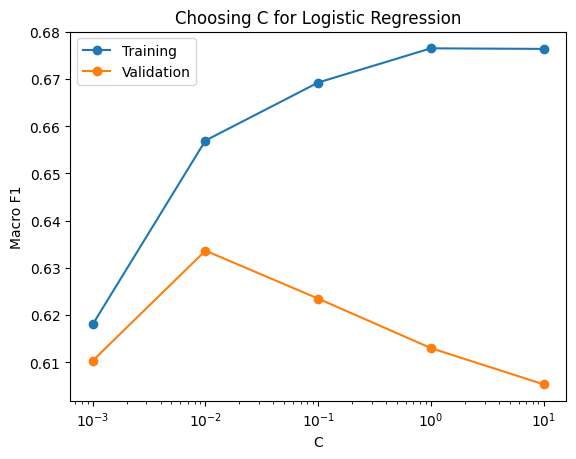

In [28]:
# Comparing training and validation scores for each C value
plt.plot(results["C"], results["Training"], marker="o", label="Training")
plt.plot(results["C"], results["Validation"], marker="o", label="Validation")
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("Macro F1")
plt.title("Choosing C for Logistic Regression")
plt.legend()
plt.show()

## Validating the results

**Cross-validation scores**

For the 5 rounds of cross-validation, the model got an average Macro F1 of 63.4%, accuracy of 75.0% and top-2 accuracy of 90.9%. The scores did not change much from one round to the next. This shows the results are steady and did not just happen because of a lucky split of the data

In [29]:
from sklearn.metrics import make_scorer, top_k_accuracy_score

# The three scores we use to measure the model
top2 = make_scorer(top_k_accuracy_score, k=2, response_method="predict_proba")
metrics = {"macro_f1": "f1_macro", "accuracy": "accuracy", "top2": top2}

# Running 5-fold cross-validation with the best C value and the area weights
model = LogisticRegression(max_iter=3000, C=best_C)
cv_scores = cross_validate(model, X_train, y_train, cv=folds, scoring=metrics, n_jobs=-1,
                           params={"sample_weight": sample_weights})

# Score for each round and the average and spread
print("Macro F1:", cv_scores["test_macro_f1"].round(3), "mean", cv_scores["test_macro_f1"].mean().round(3), "std", cv_scores["test_macro_f1"].std().round(3))
print("Accuracy:", cv_scores["test_accuracy"].round(3), "mean", cv_scores["test_accuracy"].mean().round(3), "std", cv_scores["test_accuracy"].std().round(3))
print("Top-2:   ", cv_scores["test_top2"].round(3), "mean", cv_scores["test_top2"].mean().round(3), "std", cv_scores["test_top2"].std().round(3))

Macro F1: [0.627 0.643 0.641 0.622 0.637] mean 0.634 std 0.008
Accuracy: [0.742 0.761 0.753 0.742 0.751] mean 0.75 std 0.007
Top-2:    [0.904 0.914 0.914 0.906 0.906] mean 0.909 std 0.004


**Testing the model**

On the test data it got 63.7% Macro F1, 75.2% accuracy and 90.6% top-2 accuracy. These are similar to the cross-validation scores. This shows that the model works well on new data.

The model does best on Web Development (0.85) and Mobile Development (0.72). It does worst on Cloud & Infrastructure (0.44) because many DevOps tools are also used by web developers

In [30]:
from sklearn.metrics import classification_report

# Training on all the training data, then predicting on the test data
model.fit(X_train, y_train, sample_weight=sample_weights)
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)

print("Macro F1:", round(f1_score(y_test, predictions, average="macro"), 3))
print("Accuracy:", round(accuracy_score(y_test, predictions), 3))
print("Top-2 accuracy:", round(top_k_accuracy_score(y_test, probabilities, k=2, labels=model.classes_), 3))
print()

# Scores for each area
print(classification_report(y_test, predictions, zero_division=0))

Macro F1: 0.637
Accuracy: 0.752
Top-2 accuracy: 0.906

                           precision    recall  f1-score   support

   Cloud & Infrastructure       0.47      0.41      0.44       380
                Data & AI       0.61      0.65      0.63       599
       Mobile Development       0.65      0.82      0.72       186
Systems, Embedded & Games       0.51      0.59      0.55       557
          Web Development       0.86      0.83      0.85      3443

                 accuracy                           0.75      5165
                macro avg       0.62      0.66      0.64      5165
             weighted avg       0.76      0.75      0.75      5165



**Confusion matrix**

Most of the model's mistakes are guessing Web Development when the person is in another area. 37% of Cloud & Infrastructure people and 30% of Systems, Embedded & Games people were guessed as Web Development. This is because Web Development is the biggest area and shares tools like Docker, SQL and Python with these areas. Mobile Development (82%) and Web Development (83%) are the easiest to get right

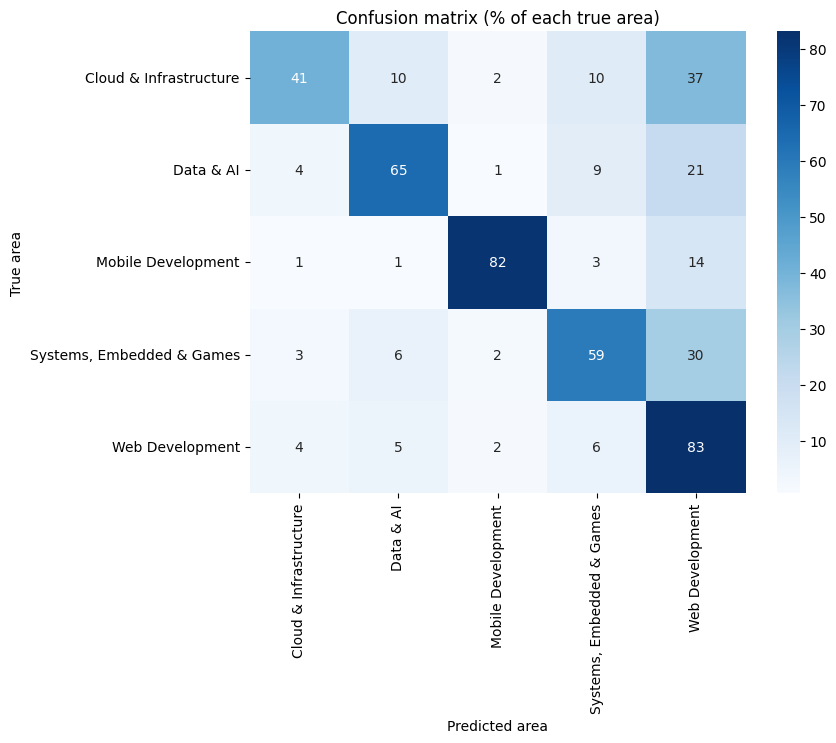

In [31]:
from sklearn.metrics import confusion_matrix

# Shows what percentage of each true area was predicted as each area
matrix = confusion_matrix(y_test, predictions, labels=model.classes_, normalize="true") * 100
matrix = pd.DataFrame(matrix, index=model.classes_, columns=model.classes_)

plt.figure(figsize=(8, 6))
sns.heatmap(matrix, annot=True, fmt=".0f", cmap="Blues")
plt.title("Confusion matrix (% of each true area)")
plt.ylabel("True area")
plt.xlabel("Predicted area")
plt.show()

**Top-2 baseline**

If we gave every student the same 2 biggest areas (Web Development and Data & AI), we would be right 78.3% of the time (baseline). Our model gets 90.6% which shows it is giving each student suggestions based on their own skills

In [32]:
# How often the true area is one of the 2 biggest areas
two_biggest = y_train.value_counts().head(2).index
top2_baseline = y_test.isin(two_biggest).mean()
print("Two biggest areas:", list(two_biggest))
print("Top-2 baseline:", round(top2_baseline, 3))

Two biggest areas: ['Web Development', 'Data & AI']
Top-2 baseline: 0.783


**Shuffled labels check**

As a test, we mixed up the areas randomly so they no longer matched the right people, then trained the model again. If our model were only picking up fake patterns, it would still score well. Instead, Macro F1 dropped to 16.1% and accuracy fell to 66.5%, which is the same as just guessing Web Development every time. This shows our real model is learning an actual link between people's skills and their career areas

In [33]:
# Mixing up the areas randomly so they no longer match the right people
y_shuffled = y_train.sample(frac=1, random_state=42)
shuffled_weights = y_shuffled.map(area_weights).values

# Training the same model on the shuffled areas
shuffled_model = LogisticRegression(max_iter=3000, C=best_C)
shuffled_model.fit(X_train, y_shuffled.values, sample_weight=shuffled_weights)
shuffled_predictions = shuffled_model.predict(X_test)
shuffled_probabilities = shuffled_model.predict_proba(X_test)

# These scores should fall to the baseline level
print("Macro F1:", round(f1_score(y_test, shuffled_predictions, average="macro"), 3))
print("Accuracy:", round(accuracy_score(y_test, shuffled_predictions), 3))
print("Top-2 accuracy:", round(top_k_accuracy_score(y_test, shuffled_probabilities, k=2, labels=shuffled_model.classes_), 3))

Macro F1: 0.161
Accuracy: 0.665
Top-2 accuracy: 0.778


## Step 2: Ranking the careers inside each area

Once the area is found, a smaller Logistic Regression model inside that area ranks its careers. For example, the Data & AI model only chooses between Data Scientist / AI-ML Engineer, Data Engineer/Analyst and Academic Researcher. Mobile Development has only one career so it does not need a model.

The table shows how each career model does on test people who are really in that area. The right career is in the top 2 between 87.6% and 92.0% of the time. Data & AI (65.4% Macro F1) and Systems, Embedded & Games (65.0%) do best. Cloud & Infrastructure is the hardest (46.4%) because Cybersecurity and IT Support have very few people

In [34]:
# The specific career of each person in the training and test data
careers_train = careers.loc[X_train.index]
careers_test = careers.loc[X_test.index]

career_models = {}
rows = []
for area in sorted(y_train.unique()):
    # People in this area
    in_train = (y_train == area).values
    in_test = (y_test == area).values
    area_careers = careers_train[in_train]

    # Mobile Development has only one career, so it does not need a model
    if area_careers.nunique() == 1:
        career_models[area] = area_careers.iloc[0]
        continue

    # Smaller careers get more weight, the same way as for the areas
    counts = area_careers.value_counts()
    weights = area_careers.map((len(area_careers) / (len(counts) * counts)) ** 0.5).values

    career_model = LogisticRegression(max_iter=3000, C=0.1)
    career_model.fit(X_train[in_train], area_careers, sample_weight=weights)
    career_models[area] = career_model

    # Testing on people from the test data who are really in this area
    pred = career_model.predict(X_test[in_test])
    prob = career_model.predict_proba(X_test[in_test])
    rows.append({
        "Area": area,
        "Careers": counts.size,
        "Macro F1": f1_score(careers_test[in_test], pred, average="macro"),
        "Accuracy": accuracy_score(careers_test[in_test], pred),
        "Top-2": top_k_accuracy_score(careers_test[in_test], prob, k=2, labels=career_model.classes_),
    })

pd.DataFrame(rows).set_index("Area").round(3)

,Careers,Macro F1,Accuracy,Top-2
Area,,,,
Cloud & Infrastructure,3,0.464,0.666,0.876
Data & AI,3,0.654,0.651,0.920
"Systems, Embedded & Games",3,0.650,0.716,0.907
Web Development,4,0.555,0.630,0.880


# Q4: Further Validation: Comparing Other Models

**Comparing different models**

To see if Logistic Regression is a good choice, we train 8 other models with the same data, the same split, the same 5-fold cross-validation, the same area weights and the same scores. We also tried a combined model that averages the percentages from Logistic Regression, HistGradientBoosting and LightGBM.

KNN and the Neural Network cannot take weights, so they are trained without them

In [36]:
from sklearn.naive_bayes import BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, VotingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import LabelEncoder
from lightgbm import LGBMClassifier
import warnings
warnings.filterwarnings("ignore")

# Settings for the two boosting models, also used inside the combined model
hgb = HistGradientBoostingClassifier(learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=50,
                                     l2_regularization=1.0, max_iter=400, random_state=42)
lgbm = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8,
                      subsample_freq=1, colsample_bytree=0.5, verbose=-1, random_state=42)

# The models we compare with Logistic Regression
models = {
    "Logistic Regression": LogisticRegression(max_iter=3000, C=best_C),
    "Naive Bayes": BernoulliNB(),
    "KNN": KNeighborsClassifier(n_neighbors=25),
    "Decision Tree": DecisionTreeClassifier(max_depth=12, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1),
    "Neural Network": MLPClassifier(hidden_layer_sizes=(128,), alpha=0.01, max_iter=200,
                                    early_stopping=True, random_state=42),
    "HistGradientBoosting": hgb,
    "LightGBM": lgbm,
    "Combined (LR + HGB + LightGBM)": VotingClassifier([
        ("lr", LogisticRegression(max_iter=3000, C=best_C)), ("hgb", hgb), ("lgbm", lgbm)],
        voting="soft"),
}

# KNN and the Neural Network cannot take weights, so they are trained without them
no_weights = ["KNN", "Neural Network"]

# The Neural Network's early stopping needs numbers instead of area names,
# so it gets an encoded copy of the labels
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

# LightGBM does not accept some characters in column names (like C#), so plain arrays are used
X_train_values = X_train.values
X_test_values = X_test.values

rows = []
for name in models:
    m = models[name]
    fit_params = {} if name in no_weights else {"sample_weight": sample_weights}

    # Neural Network uses the encoded labels, every other model uses the original ones
    if name == "Neural Network":
        y_tr, y_te = y_train_enc, y_test_enc
    else:
        y_tr, y_te = y_train, y_test

    # Same 5 folds and same scores for every model
    cv = cross_validate(m, X_train_values, y_tr, cv=folds, scoring=metrics, n_jobs=-1, params=fit_params)

    # Training on the training data and testing on the test data
    m.fit(X_train_values, y_tr, **fit_params)
    pred = m.predict(X_test_values)
    prob = m.predict_proba(X_test_values)

    # Saving the results for this model
    rows.append({
        "Model": name,
        "CV Macro F1": cv["test_macro_f1"].mean(),
        "CV Accuracy": cv["test_accuracy"].mean(),
        "CV Top-2": cv["test_top2"].mean(),
        "Test Macro F1": f1_score(y_te, pred, average="macro"),
        "Test Accuracy": accuracy_score(y_te, pred),
        "Test Top-2": top_k_accuracy_score(y_te, prob, k=2, labels=m.classes_),
    })
    print(name, "done")

# Putting all results in one table, sorted by Macro F1
comparison = pd.DataFrame(rows).set_index("Model").round(3)
comparison = comparison.sort_values("Test Macro F1", ascending=False)
comparison

Logistic Regression done
Naive Bayes done
KNN done
Decision Tree done
Random Forest done
Neural Network done
HistGradientBoosting done
LightGBM done
Combined (LR + HGB + LightGBM) done


,CV Macro F1,CV Accuracy,CV Top-2,Test Macro F1,Test Accuracy,Test Top-2
Model,,,,,,
Combined (LR + HGB + LightGBM),0.645,0.763,0.919,0.646,0.765,0.914
LightGBM,0.640,0.766,0.921,0.639,0.763,0.914
Logistic Regression,0.634,0.750,0.909,0.637,0.752,0.906
HistGradientBoosting,0.633,0.753,0.914,0.630,0.751,0.908
Neural Network,0.617,0.770,0.922,0.606,0.768,0.915
Random Forest,0.557,0.760,0.917,0.563,0.759,0.917
KNN,0.518,0.741,0.891,0.526,0.740,0.889
Decision Tree,0.513,0.671,0.854,0.497,0.668,0.848
Naive Bayes,0.488,0.559,0.776,0.484,0.557,0.775


**Comparison chart**

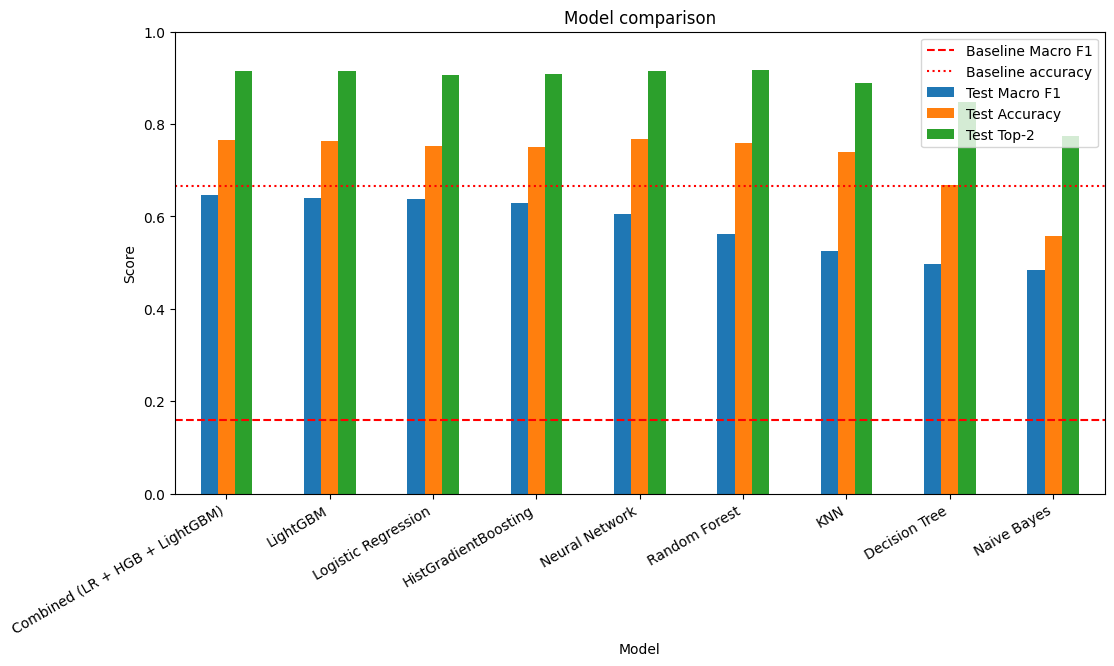

In [37]:
# Comparing the test scores of all models with the baseline shown as red lines
comparison[["Test Macro F1", "Test Accuracy", "Test Top-2"]].plot(kind="bar", figsize=(12, 6))
plt.axhline(baseline_f1, color="red", linestyle="--", label="Baseline Macro F1")
plt.axhline(baseline_accuracy, color="red", linestyle=":", label="Baseline accuracy")
plt.title("Model comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.legend()
plt.show()

## How we trained the model

We used the Stack Overflow Developer Survey and cleaned it down to 25,822 developers. We kept only what a student can tell the app: the skills they use, the skills they want to work with, the tools they use, years of coding, work experience and education.

Our first model tried to pick 1 of 15 careers and its Macro F1 was only 34.8%, because many careers share the same skills. So we grouped the careers into 5 career areas, removed QA/Test and gave smaller areas more weight. The model first picks the area and then a smaller model ranks the careers inside it.

We trained a Logistic Regression model on 80% of the data and tested it on the other 20%. We used 5-fold cross-validation to choose the best settings.

The model gets 63.7% Macro F1, compared to 16.0% if we always guessed the most common area. It picks the right area 75.2% of the time and the right area is in its top 2 90.6% of the time.

We also trained eight other models the same way. The combined model and LightGBM did slightly better (less than 1 point), but we kept Logistic Regression because it is simpler, faster and easier to explain, and it is easy to run inside an Android app.